# 1. Imports

In [108]:
import pandas as pd
import numpy as np

import boto3 # Bibliothèque Python d'AWS qui permet de faire comme aws s3 mais de récupérer le tout en données Python
from botocore import UNSIGNED # On importe des éléments du package botocore installé avec boto3 pour ne pas avoir à s'identifier
from botocore.config import Config

import os

import openslide
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

import time
from PIL import Image # bibliothèque pour manipuler des images (OpenSlide renvoie en image PIL avec read_region)

# 2. Première exploration du bucket AWS S3 camelyon-dataset

Les données du dataset CAMELYON17 sont stockées sur AWS qui héberge gratuitement certaines données utiles à la recherche. Le service de stockage d'AWS s'appelle S3 et est organisé en grands dossiers appelés buckets.

Nous utilisons l'outil AWS CLI, un programme AWS qui permet de consulter les données sur AWS en lignes de commandes :
- ! car le code n'est pas du Python donc à envoyer au terminal du système
- aws s3 ls : commande permettant de lister les fichiers (aws est le programme AWS CLI, s3 est le service utilisé, ls est l'action qui permet de lister le contenu).
- --no-sign-request : option permettant d'accéder aux données sans s'identifier.
- s3://camelyon-dataset/ : l'adresse comprennant le service utilisé (S3) et le nom du bucket. On pourra ensuite aller chercher dans un chemin particulier à l'intérieur du bucket. Le nom du bucket a été trouvé sur cette page : https://registry.opendata.aws/camelyon/.

In [61]:
!aws s3 ls --no-sign-request s3://camelyon-dataset/

                           PRE CAMELYON16/
                           PRE CAMELYON17/


PRE signifie prefix. C’est la façon dont S3 indique un "dossier". On observe que camelyon-dataset contient deux dossiers : CAMELYON16 et CAMELYON17. CAMELYON16 est un autre challenge, lancé avant CAMELYON17.

In [62]:
!aws s3 ls --no-sign-request s3://camelyon-dataset/CAMELYON17/ 

                           PRE annotations/
                           PRE evaluation/
                           PRE images/
                           PRE masks/
2022-09-28 11:15:29          0 
2022-09-28 14:49:30       3464 README.md
2022-09-28 14:49:33      71099 checksums.md5
2022-09-29 04:02:24       7260 license.txt
2022-09-29 04:05:37      18689 stages.csv


Le "dossier" CAMELYON17/ contient à sa racine 4 autres dossiers et 4 fichiers :
- Les dossiers :
  - images/
  - annotations/
  - masks/
  - evaluation/
- Les fichiers :
  - stages.csv
  - README.md
  - license.txt
  - checksums.md5

### 2.1. Fichier `README.md`


Nous commençons par récupérer le README afin de pouvoir le lire.

In [63]:
os.makedirs("../data/raw", exist_ok=True)
!aws s3 cp --no-sign-request s3://camelyon-dataset/CAMELYON17/README.md ../data/raw/

# cp pour copier à l'endroit indiqué

Completed 3.4 KiB/3.4 KiB (4.2 KiB/s) with 1 file(s) remaining
download: s3://camelyon-dataset/CAMELYON17/README.md to ..\data\raw\README.md


Voici ce que nous apprend le README du dataset CAMELYON17 (copié dans data/) :

- Les données :
  - 1 000 lames entières (WSI) de ganglions sentinelles, venant de 5 hopitaux aux Pays-Bas : Radboud UMC, Canisius-Wilhelmina, UMC Utrecht, Rijnstate et LabPON.
  - Les données sont réparties entre entrainement et test : 20 patientes par centre dans chaque jeu, soit 100 patientes
  (=500 lames) pour l'entraînement et 100 patientes (=500 lames) pour le test.
  - 5 lames par patiente, chaque lame provenant d'un ganglion sentinelle différent.

- Le contenu des dossiers :
  - images/ : les 1 000 lames, au format TIFF multirésolution (convertis avec le logiciel ASAP)
  - annotations/ : les contours des métastases au format XML (lisibles dans ASAP) pour 10 lames par centre, soit 50 lames, annotées de façon exhaustive. Il y a deux groupes d'annotations (attribut `PartOfGroup`) : Tumor pour les zones tumorales, Exclusion pour les zones non tumorales découpées à l'intérieur des zones "Tumor". A noter : les métastases micro et macro sont annotées de manière exhaustive mais pas les ITC. **A vérifier : les lames annotées font à priori parti du jeu d'entrainement.**
  - masks/ : des masques tout prêts pour 100 lames : les 50 lames annotées ainsi que 50 lames négatives choisies au hasard. Voici les valeurs de chaque pixel : 0 pour le fond (verre), 1 pour le tissu sain et 2 pour une tumeur. Les zones tumorales viennent des contours XML. **A vérifier : idem, il s'agirait à priori de lames du jeu d'entrainement.**

- Le contenu des fichiers :
  - stages.csv : les étiquettes avec le stade pN de chaque patiente et la classe de chaque lame
  (négative, ITC, micro, macro). **À vérifier : entraînement seulement ou aussi test ?**
  - license.txt : la licence d'utilisation.
  - checksums.md5 : les empreintes MD5 de tous les fichiers, pour vérifier qu'une lame
  téléchargée n'est pas abîmée (commande md5sum).

- La description complète du challenge peut être trouvée via ce lien : https://camelyon17.grand-challenge.org

### 2.2. Fichier `stages.csv`

Nous le copions tout d'abord tel quel dans data/raw/.

In [64]:
!aws s3 cp --no-sign-request s3://camelyon-dataset/CAMELYON17/stages.csv ../data/raw/

Completed 18.3 KiB/18.3 KiB (18.9 KiB/s) with 1 file(s) remaining
download: s3://camelyon-dataset/CAMELYON17/stages.csv to ..\data\raw\stages.csv


Nous le découvrons ensuite via pandas.

In [65]:
stages = pd.read_csv("../data/raw/stages.csv")
stages

,patient,stage,center
0,patient_000.zip,pN0,0
1,patient_000_node_0.tif,negative,0
2,patient_000_node_1.tif,negative,0
3,patient_000_node_2.tif,negative,0
4,patient_000_node_3.tif,negative,0
...,...,...,...
595,patient_099_node_0.tif,negative,4
596,patient_099_node_1.tif,negative,4
597,patient_099_node_2.tif,negative,4
598,patient_099_node_3.tif,negative,4


In [66]:
print(f"Le fichier contient {stages.shape[0]} lignes et {stages.shape[1]} colonnes.")

Le fichier contient 600 lignes et 3 colonnes.


Les 600 lignes concernent 100 patientes. Pour chaque patiente :
- 1 ligne au niveau patiente soit 100 lignes (ex : patient_000.zip où 'patient_000' identifie la patiente). Les patientes sont numérotées de 000 à 099.
- 5 lignes au niveau lame soit 5*100 = 500 lames (ex : patient_000_node_0.tif où 'patient_000' identifie la patiente et 'node_0' identifie le ganglion concerné par la lame). Les ganglions sont numérotés de 0 à 4.

Il y a 3 colonnes :
- `patient` qui est le nom du fichier qui identifie la patiente / la lame
- `stage` qui indique le stade pN pour les lignes au niveau patiente et la classe de la lame (negative, ITC, micro, macro) pour les lignes au niveau lame
- `center` qui identifie le centre médical

Il s'agit donc ici des données d'entrainement.

### 2.3. Dossier `images/`

In [67]:
s3 = boto3.client("s3", region_name="us-west-2", config=Config(signature_version=UNSIGNED)) # On crée un client = un objet qui sait parler au service S3.
BUCKET, PREFIX = "camelyon-dataset", "CAMELYON17/"

def lister(dossier):
    """Renvoie un DataFrame (fichier, taille en octets, en Mo et en Go) des fichiers d'un dossier d'AWS."""
    fichiers = []
    paginateur = s3.get_paginator("list_objects_v2") # list_objects_v2 est l’opération d’AWS qui liste des fichiers. get_paginator crée un paginateur qui permettra de demander toutes les pages une par une, si plusieurs.
    pages = paginateur.paginate(Bucket=BUCKET, Prefix=PREFIX + dossier) # .paginate() est une méthode de l’objet paginateur qui reçoit les paramètres de la requête et renvoie un objet itérable.
    for page in pages:
        for fichier in page.get("Contents", []): # Chaque page est un dictionnaire Python et la liste des fichiers est dans "Contents"
            nom = fichier["Key"].split("/")[-1] # On ne garde que le nom
            if nom:
                fichiers.append({"fichier": nom, "taille_octets": fichier["Size"], "taille_Mo": round(fichier["Size"]/1000000,2), "taille_Go": round(fichier["Size"]/1000000000,2)})
    return pd.DataFrame(fichiers)

In [68]:
images = lister("images/")

In [69]:
print(f"Le dossier images/ contient {len(images)} fichiers (attendu : un par lame (1000)).")

Le dossier images/ contient 1000 fichiers (attendu : un par lame (1000)).


In [70]:
images

,fichier,taille_octets,taille_Mo,taille_Go
0,patient_000_node_0.tif,2837938781,2837.94,2.84
1,patient_000_node_1.tif,2212330723,2212.33,2.21
2,patient_000_node_2.tif,2308484849,2308.48,2.31
3,patient_000_node_3.tif,2208844437,2208.84,2.21
4,patient_000_node_4.tif,1905999125,1906.00,1.91
...,...,...,...,...
995,patient_199_node_0.tif,2030096771,2030.10,2.03
996,patient_199_node_1.tif,5331147711,5331.15,5.33
997,patient_199_node_2.tif,4905934953,4905.93,4.91
998,patient_199_node_3.tif,8109937725,8109.94,8.11


### 2.4. Dossier `annotations/`

In [71]:
annotations = lister("annotations/")

In [72]:
print(f"Le dossier annotations/ contient {len(annotations)} fichiers (attendu : un par lame annotée (50)).")

Le dossier annotations/ contient 50 fichiers (attendu : un par lame annotée (50)).


In [73]:
annotations

,fichier,taille_octets,taille_Mo,taille_Go
0,patient_004_node_4.xml,2647,0.00,0.0
1,patient_009_node_1.xml,28584,0.03,0.0
2,patient_010_node_4.xml,61142,0.06,0.0
3,patient_012_node_0.xml,26909,0.03,0.0
4,patient_015_node_1.xml,25923,0.03,0.0
5,patient_015_node_2.xml,8638,0.01,0.0
6,patient_016_node_1.xml,1014,0.00,0.0
7,patient_017_node_1.xml,1568,0.00,0.0
8,patient_017_node_2.xml,82322,0.08,0.0
9,patient_017_node_4.xml,21763,0.02,0.0


### 2.5. Dossier `masks/`

In [74]:
masques = lister("masks/")

In [75]:
print(f"Le dossier masks/ contient {len(masques)} fichiers (attendu : un par lame annotée (50) + 50 lames négatives = 100).")

Le dossier masks/ contient 100 fichiers (attendu : un par lame annotée (50) + 50 lames négatives = 100).


In [76]:
masques

,fichier,taille_octets,taille_Mo,taille_Go
0,patient_000_node_4_mask.tif,7796338,7.80,0.01
1,patient_001_node_3_mask.tif,15457862,15.46,0.02
2,patient_003_node_1_mask.tif,13115412,13.12,0.01
3,patient_004_node_2_mask.tif,16394236,16.39,0.02
4,patient_004_node_4_mask.tif,15510926,15.51,0.02
...,...,...,...,...
95,patient_093_node_1_mask.tif,36676346,36.68,0.04
96,patient_096_node_0_mask.tif,26086418,26.09,0.03
97,patient_097_node_2_mask.tif,32853738,32.85,0.03
98,patient_099_node_3_mask.tif,13350938,13.35,0.01


# 3. Préparation des données utiles

### 3.1. Tableaux patientes et lames à partir de stages.csv

In [77]:
patientes = stages[stages["patient"].str.endswith(".zip")].copy() # .str pour appliquer une méthode string à chaque élément de la colonne patient
patientes["patiente"] = patientes["patient"].str.extract(r"patient_(\d+)").astype(int) # La partie à récupérer est entre () dans la regex
patientes = patientes.rename(columns={"stage": "stade_pN", "center": "centre_medical"})
patientes = patientes[["patiente", "centre_medical", "stade_pN"]].reset_index(drop=True)
patientes.head()

,patiente,centre_medical,stade_pN
0,0,0,pN0
1,1,0,pN0
2,2,0,pN0
3,3,0,pN0
4,4,0,pN0(i+)


In [78]:
lames = stages[stages["patient"].str.endswith(".tif")].copy()
lames[["patiente", "ganglion"]] = lames["patient"].str.extract(r"patient_(\d+)_node_(\d+)").astype(int)
lames = lames.rename(columns={"patient": "lame", "stage": "classe", "center": "centre_medical"})
lames["lame"] = lames["lame"].str.replace(".tif", "", regex=False)
lames = lames[["lame", "patiente", "ganglion", "centre_medical", "classe"]].reset_index(drop=True)
lames.head()

,lame,patiente,ganglion,centre_medical,classe
0,patient_000_node_0,0,0,0,negative
1,patient_000_node_1,0,1,0,negative
2,patient_000_node_2,0,2,0,negative
3,patient_000_node_3,0,3,0,negative
4,patient_000_node_4,0,4,0,negative


### 3.2. Tableau lames complété des informations suivantes : annotation, masque, taille en Go du fichier TIFF

In [79]:
lames["annotee"] = (lames["lame"] + ".xml").isin(annotations["fichier"])
lames["masque"] = (lames["lame"] + "_mask.tif").isin(masques["fichier"])
lames["taille_Go"] = (lames["lame"] + ".tif").map(images.set_index("fichier")["taille_Go"])
lames.head(10)

,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
0,patient_000_node_0,0,0,0,negative,False,False,2.84
1,patient_000_node_1,0,1,0,negative,False,False,2.21
2,patient_000_node_2,0,2,0,negative,False,False,2.31
3,patient_000_node_3,0,3,0,negative,False,False,2.21
4,patient_000_node_4,0,4,0,negative,False,True,1.91
5,patient_001_node_0,1,0,0,negative,False,False,2.23
6,patient_001_node_1,1,1,0,negative,False,False,1.39
7,patient_001_node_2,1,2,0,negative,False,False,1.41
8,patient_001_node_3,1,3,0,negative,False,True,3.56
9,patient_001_node_4,1,4,0,negative,False,False,2.04


In [80]:
print(lames["annotee"].sum(), "lames annotées (attendu 50).")
print(lames["masque"].sum(), "lames avec masque (attendu 100).")
print(f"{round(lames["taille_Go"].sum())} Go au total pour les 500 lames et {round(lames["taille_Go"].mean(), 2)} Go en moyenne par lame.")

50 lames annotées (attendu 50).
100 lames avec masque (attendu 100).
1461 Go au total pour les 500 lames et 2.92 Go en moyenne par lame.


### 3.3. Tableau patientes complété des informations suivantes : nombre de lames annotées, nombre de lame avec masque, taille totale des images

In [81]:
resume = lames.groupby("patiente").agg(
    nb_annotees=("annotee", "sum"),
    nb_masques=("masque", "sum"),
    taille_Go=("taille_Go", "sum"),
).reset_index()

patientes = patientes.merge(resume, on="patiente")
patientes.head(10)

,patiente,centre_medical,stade_pN,nb_annotees,nb_masques,taille_Go
0,0,0,pN0,0,1,11.48
1,1,0,pN0,0,1,10.63
2,2,0,pN0,0,0,14.21
3,3,0,pN0,0,1,12.66
4,4,0,pN0(i+),1,2,13.86
5,5,0,pN0(i+),0,1,12.97
6,6,0,pN0(i+),0,1,13.38
7,7,0,pN1mi,0,0,11.78
8,8,0,pN1mi,0,1,11.12
9,9,0,pN1mi,1,2,14.80


# 4. Première analyse du dataset

In [82]:
print((patientes["nb_annotees"] > 0).sum(), "patientes ont au moins une lame annotée")
print((patientes["nb_masques"] > 0).sum(), "patientes ont au moins un masque")

43 patientes ont au moins une lame annotée
68 patientes ont au moins un masque


Concernant les lames annotées, celles-ci sont réparties entre les patientes (43 patientes avec une lame annotée pour 50 lames annotées en tout donc seulement très peu de patientes ont a priori plusieurs lames annotées).

In [83]:
lames["classe"].value_counts()

classe
negative    318
macro        87
micro        59
itc          36
Name: count, dtype: int64

La plupart des lames sont négatives. Il faudra avoir en tête ce déséquilibre des classes et le traiter.
A noter aussi qu'il faut, du coup, que le modèle apprenne bien sur les lames négatives car s'il apprend mal sur elles, il fera beaucoup d'erreurs + s'il ne se trompe que sur un seul patch, la lame est mal classée et la patiente également... Même si ce sont les faux négatifs qui restent les plus graves, les faux positifs seront à avoir en tête aussi.

# 5. Prototype pour comprendre les étapes du travail à réaliser

### 5.1. Etape 1 - Le modèle de patch

#### 5.1.1. Téléchargement de quelques lames pour le prototype

Il nous faut sélectionner des données pour :
- Le set d'entrainement
- Le set de validation
- Le set de test

La logique : le set d'entrainement nous sert pour entrainer le modèle, le set de validation pour voir les performances du modèle et ajuster nos réglages sans toucher au test, le set de test pour voir la performance finale.

Choix des lames pour ce prototype, en réduisant le nombre au maximum :
- Entrainement : choix de 3 lames dont 2 annotées avec masque et 1 négative non annotée avec masque. L'intérêt d'ajouter des lames négatives avec masque est que pour ces lames, nous sommes sûrs que les patchs sont tous sains. Pour les lames annotées, il est précisé que les ITC ne sont pas entourées de manière exhaustive donc un patch étiqueté "sain" peut ne pas l'être. Le modèle peut ainsi bien apprendre, avec les lames négatives, à quoi ressemble une lame entièrement saine. Par ailleurs, pour les lames annotées, nous prendrons des lames avec macro-métastases ou, si non suffisantes, avec micro-metastases pour avoir assez de patchs tumoraux pour que le modèle apprenne (pour ce prototype).
- Validation : 1 lame annotée avec masque pour régler notre modèle. Il nous faut une lame annotée car on teste sur cette lame pour ajuster les réglages donc il nous faut la "bonne réponse" = l'annotation de la lame. Toutes les lames annotées ont un masque : c'est la "traduction en image" des annotations avec en plus la distinction entre le fond de la lame et le tissu. De même, on choisira une lame macro si possible, sinon micro.
- Test : on prendra 5 lames d'une même patiente pour pouvoir faire le test de bout en bout (du patch au stade pN). La chaine comprend 3 étapes : patch, lame, patiente. Il nous faut au moins une lame annotée sur cette patiente : on aura ainsi la "bonne réponse" patch par patch pour pouvoir évaluer le modèle de patch seul. Ensuite on a l'information de la classe de la lame pour toutes les lames et l'information du stade pN pour toutes les patientes. Ce sera forcément une patiente non pN0 avec une lame annotée.

C’est le masque ou l'annotation qui nous donnera l’étiquette de chaque patch donc il nous faut des lames avec annotation / masque pour l'entrainement et la validation + au moins 1 parmi les 5 de la patiente pour le test.

**A voir si on utilise les masques uniquement ou s'il faudra utiliser les annotations pour plus de précision.**

A noter : 
- Concernant la fuite des données : nous ne pouvons pas prendre des lames d'une même patiente dans plusieurs de ces sets (par exemple lame 1 de la patiente 1 dans le set d'entrainement et lame 2 de la patiente 1 dans le set de validation) car cela entraine une fuite des données : le modèle connaitrait déjà bien les lames de cette patiente qui se ressemblent forcément plus (cellules tumorales qui se ressemblent, même centre médical avec mêmes couleurs et même scanner...).
- Pour le prototype, comme on aura peu de lames, on prendra des lames de patientes différentes (mais pas forcément pour la solution finale : on pourra avoir 2 lames d'une même patiente en entrainement par exemple).
- Concernant le domain shift : la question est de savoir comment on construit nos sets pour que notre modèle soit robuste et qu'il n'apprenne pas bien que sur un seul centre médical par exemple.  Il y a plusieurs options pour traiter ça :
   - Si on met dans chaque set des lames de chaque centre, le modèle apprend sur tous les centres. On peut étudier le domain shift en analysant les résultats du test centre par centre voir si l'un est moins bon. Par contre, on ne pourra pas voir si notre modèle est efficace sur un centre jamais vu.
   - L'autre option est de tester le domain shift ainsi : dans le test on ne prend des lames que d'un centre, dans la validation d'un autre, et dans l'entrainement les autres. C'est ce que fait WILDS.
   - On peut combiner les deux : comparer un entraînement avec tous les centres et un entraînement avec un centre gardé de côté. On mesure la performance sur ce centre dans les deux cas et on compare : si moins bon quand gardé de côté, c'est l'effet du domain shift.
   - Pour le prototype, comme on a peu de lames, on va d'abord voir si le modèle de base, hors effet domain shift, fonctionne et donc on va prendre des lames d'un même centre.

In [84]:
patientes_candidates_test = patientes[(patientes["nb_annotees"] > 0)] # Toutes les patientes avec au moins une lame annotée
patiente_test = patientes_candidates_test.sort_values("taille_Go").iloc[0]["patiente"] # On prend celle pour laquelle la taille des fichiers est la plus petite

print(f"Patiente de test retenue : patiente n°{patiente_test}.")
lames_test = lames[lames["patiente"] == patiente_test]
lames_test

Patiente de test retenue : patiente n°99.


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
495,patient_099_node_0,99,0,4,negative,False,False,0.45
496,patient_099_node_1,99,1,4,negative,False,False,0.88
497,patient_099_node_2,99,2,4,negative,False,False,1.03
498,patient_099_node_3,99,3,4,negative,False,True,0.65
499,patient_099_node_4,99,4,4,macro,True,True,0.90


In [85]:
patientes_deja_prises = [patiente_test]
centre_patiente_test = lames_test["centre_medical"].iloc[0]

lames_candidates_macro_annotees = lames[
    lames["annotee"]
    & (lames["classe"] == "macro")
    & (lames["centre_medical"] == centre_patiente_test)
    & ~lames["patiente"].isin(patientes_deja_prises)
].sort_values("taille_Go")

lames_candidates_micro_annotees = lames[
    lames["annotee"]
    & (lames["classe"] == "micro")
    & (lames["centre_medical"] == centre_patiente_test)
    & ~lames["patiente"].isin(patientes_deja_prises)
].sort_values("taille_Go")

lames_candidates_negatives_masque = lames[
    lames["masque"]
    & (lames["classe"] == "negative")
    & (lames["centre_medical"] == centre_patiente_test)
    & ~lames["patiente"].isin(patientes_deja_prises)
].sort_values("taille_Go")

print("LAMES CANDIDATES POUR L'ENTRAINEMENT ET LE TEST")

print("Lames candidates macro et annotées")
display(lames_candidates_macro_annotees)

print("Lames candidates micro et annotées")
display(lames_candidates_micro_annotees)

print("Lames candidates négatives avec masque")
display(lames_candidates_negatives_masque)

LAMES CANDIDATES POUR L'ENTRAINEMENT ET LE TEST
Lames candidates macro et annotées


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
461,patient_092_node_1,92,1,4,macro,True,True,0.88
480,patient_096_node_0,96,0,4,macro,True,True,1.04


Lames candidates micro et annotées


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
448,patient_089_node_3,89,3,4,micro,True,True,0.52
441,patient_088_node_1,88,1,4,micro,True,True,0.91


Lames candidates négatives avec masque


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
419,patient_083_node_4,83,4,4,negative,False,True,0.31
432,patient_086_node_2,86,2,4,negative,False,True,0.75
405,patient_081_node_0,81,0,4,negative,False,True,0.80
466,patient_093_node_1,93,1,4,negative,False,True,0.83
414,patient_082_node_4,82,4,4,negative,False,True,0.85
462,patient_092_node_2,92,2,4,negative,False,True,0.92
426,patient_085_node_1,85,1,4,negative,False,True,1.20
487,patient_097_node_2,97,2,4,negative,False,True,1.37
447,patient_089_node_2,89,2,4,negative,False,True,2.34


In [86]:
selection = {
    "entrainement": ["patient_089_node_3", "patient_096_node_0", "patient_083_node_4"],
    "validation": ["patient_092_node_1"],
    "test": list(lames_test["lame"]),
}

lignes = [(nom_set, lame) for nom_set, liste_lames in selection.items() for lame in liste_lames]
selection = pd.DataFrame(lignes, columns=["set", "lame"]).merge(lames, on="lame")

display(selection)

os.makedirs("../data/prototype", exist_ok=True)
selection.to_csv("../data/prototype/selection_lames_prototype.csv", index=False)

,set,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
0,entrainement,patient_089_node_3,89,3,4,micro,True,True,0.52
1,entrainement,patient_096_node_0,96,0,4,macro,True,True,1.04
2,entrainement,patient_083_node_4,83,4,4,negative,False,True,0.31
3,validation,patient_092_node_1,92,1,4,macro,True,True,0.88
4,test,patient_099_node_0,99,0,4,negative,False,False,0.45
5,test,patient_099_node_1,99,1,4,negative,False,False,0.88
6,test,patient_099_node_2,99,2,4,negative,False,False,1.03
7,test,patient_099_node_3,99,3,4,negative,False,True,0.65
8,test,patient_099_node_4,99,4,4,macro,True,True,0.90


In [87]:
DOSSIER_IMAGES = "../data/prototype/images"
DOSSIER_MASQUES = "../data/prototype/masks"
DOSSIER_ANNOTATIONS = "../data/prototype/annotations"
os.makedirs(DOSSIER_IMAGES, exist_ok=True)
os.makedirs(DOSSIER_MASQUES, exist_ok=True)
os.makedirs(DOSSIER_ANNOTATIONS, exist_ok=True)

In [88]:
def telecharger(dossier_aws, nom_fichier, dossier_local):
    """Télécharge un fichier d'AWS (à part si déjà présent sur l'ordinateur)."""
    chemin_local = os.path.join(dossier_local, nom_fichier)
    if os.path.exists(chemin_local):
        print(f"Fichier {nom_fichier} déjà présent dans le dossier")
        return
    print(f"Téléchargement de {nom_fichier} en cours")
    s3.download_file(BUCKET, PREFIX + dossier_aws + nom_fichier, chemin_local)
    print(f"Téléchargement de {nom_fichier} terminé.")

for _, ligne in selection.iterrows(): # .iterrows() parcourt le df ligne par ligne et donne le numéro de la ligne et la ligne elle-même
    telecharger("images/", ligne["lame"] + ".tif", DOSSIER_IMAGES)
    if ligne["masque"]:
        telecharger("masks/", ligne["lame"] + "_mask.tif", DOSSIER_MASQUES)
    if ligne["annotee"]:
        telecharger("annotations/", ligne["lame"] + ".xml", DOSSIER_ANNOTATIONS)

Fichier patient_089_node_3.tif déjà présent dans le dossier
Fichier patient_089_node_3_mask.tif déjà présent dans le dossier
Fichier patient_089_node_3.xml déjà présent dans le dossier
Fichier patient_096_node_0.tif déjà présent dans le dossier
Fichier patient_096_node_0_mask.tif déjà présent dans le dossier
Fichier patient_096_node_0.xml déjà présent dans le dossier
Fichier patient_083_node_4.tif déjà présent dans le dossier
Fichier patient_083_node_4_mask.tif déjà présent dans le dossier
Fichier patient_092_node_1.tif déjà présent dans le dossier
Fichier patient_092_node_1_mask.tif déjà présent dans le dossier
Fichier patient_092_node_1.xml déjà présent dans le dossier
Fichier patient_099_node_0.tif déjà présent dans le dossier
Fichier patient_099_node_1.tif déjà présent dans le dossier
Fichier patient_099_node_2.tif déjà présent dans le dossier
Fichier patient_099_node_3.tif déjà présent dans le dossier
Fichier patient_099_node_3_mask.tif déjà présent dans le dossier
Fichier patient

#### 5.1.2. Lire les lames, annotations et masques

Les lames sont des fichiers TIFF multirésolution où chaque fichier contient la même lame à plusieurs niveaux de zoom. Il nous faut des outils particuliers pour les ouvrir (les outils classiques ne peuvent pas car trop grandes).

**Le premier outil utilisé est ASAP**
- C'est un logiciel à installer sur le pc, avec une interface graphique. C'est celui mentionné dans le chllenge. https://github.com/computationalpathologygroup/ASAP
- On l'utilisera pour visualiser les lames dans l'interface graphique d'ASAP, zommer, et afficher les annotations et masques par dessus.

**Le second utilisé est OpenSlide**
- C'est une bibliothèque Python (faire `pip install openslide-python openslide-bin`) très utilisée en histopathologie numérique.
- On l'utilisera dans le code pour lire les informations d'une lame (niveaux de zoom, dimensions, taille d'un pixel), afficher une miniature, et lire seulement la région voulue au niveau de zoom voulu, sans charger toute la lame. C'est ce qui nous permettra de découper les patchs.

On choisit d'utiliser OpenSlide et non ASAP pour le code car installation simple d'OpenSlide vs ASAP (et problèmes de version avec ASAP et les autres bibliothèques).

##### Utilisation d'ASAP

**Comprendre le visuel d'une lame :**
- Un lame correspond à 1 ganglion mais il peut y avoir plusieurs coupes du même ganglion dans une lame
- La coloration :
    - La coloration H&E colore les noyaux des cellules en violet foncé ou bleu (c'est l'hématoxyline) et le reste = le cytoplasme et les fibres, en rose (c'est l'éosine)
    - En blanc c'est une zone non numérisée
    - En gris c'est une zone numérisée mais sans tissu

**Utiliser ASAP :**
- Ouvrir le fichier TIFF pour visualiser la lame
- Pour afficher le masque en superposition, aller dans l'onglet Overlay et sélectionner le masque puis cliquer sur Enable visualization. Trois colorations apparaissent avec le masque :
    - Transparent = le fond (0)
    - Bleu = le tissu sain (1)
    - Vert = la zone tumorale (2)
- Pour afficher les annotations, aller dans l'onglet Annotations et charger le fichier des annotations
    - Les groupes d'annotation apparaissent dans l'onglet avec leurs couleurs respectives (à priori rouge pour le Tumor Group et une autre couleur pour l'Exclusion Group)


##### Utilisation d'OpenSlide

La dcumentation d'OpenSlide se trouve ici : https://openslide.org/api/python/.

On commence par ouvrir une lame avec OpenSlide et regarder sa structure. On prend pour exemple la lame patient_092_node_1.tif.

La lame numérisée n'est pas enregistrée en une seule image mais en plusieurs versions de la même image de plus en plus petites (les niveaux de zoom) donc on aura différent niveaux de zoom.

La taille de pixel est exprimée en micromètres (un millième de millimètre).

In [89]:
lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, "patient_092_node_1.tif"))

print("Nombre de niveaux de zoom :", lame.level_count)
taille_pixel_niveau0 = float(lame.properties["openslide.mpp-x"])

for niveau in range(lame.level_count):
    largeur, hauteur = lame.level_dimensions[niveau]
    facteur = lame.level_downsamples[niveau]
    taille_pixel = taille_pixel_niveau0 * facteur
    print(f"Niveau {niveau} : {largeur} x {hauteur} pixels (réduit {facteur:.0f} fois), "
          f"taille d'un pixel : {taille_pixel:.2f} µm.")

Nombre de niveaux de zoom : 10
Niveau 0 : 184320 x 93696 pixels (réduit 1 fois), taille d'un pixel : 0.25 µm.
Niveau 1 : 92160 x 46848 pixels (réduit 2 fois), taille d'un pixel : 0.50 µm.
Niveau 2 : 46080 x 23424 pixels (réduit 4 fois), taille d'un pixel : 1.00 µm.
Niveau 3 : 23040 x 11712 pixels (réduit 8 fois), taille d'un pixel : 2.00 µm.
Niveau 4 : 11520 x 5856 pixels (réduit 16 fois), taille d'un pixel : 4.00 µm.
Niveau 5 : 5760 x 2928 pixels (réduit 32 fois), taille d'un pixel : 8.00 µm.
Niveau 6 : 2880 x 1464 pixels (réduit 64 fois), taille d'un pixel : 16.00 µm.
Niveau 7 : 1440 x 732 pixels (réduit 128 fois), taille d'un pixel : 32.00 µm.
Niveau 8 : 720 x 366 pixels (réduit 256 fois), taille d'un pixel : 64.00 µm.
Niveau 9 : 360 x 183 pixels (réduit 512 fois), taille d'un pixel : 128.00 µm.


Le niveau 0 correspond à la plus grande image, en pleine résolution.

Pour comparaison, une macro-métastase de 2 mm correspond à 2000 micromètres donc environ 8000 pixels au niveau 0 et 16 au niveau 9.

La lame ouverte en exemple fait donc environ 46 mm de large et 23,4 mm de haut.

Taille de la miniature : (1000, 508)


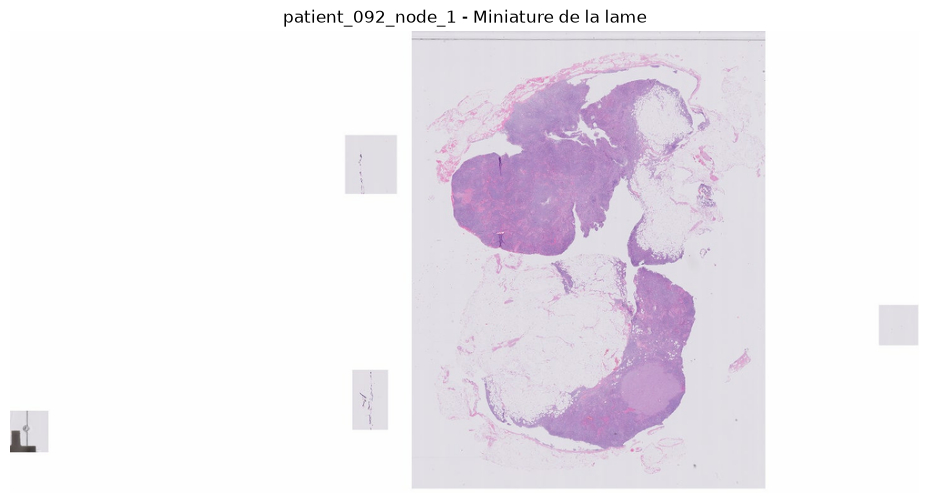

In [90]:
miniature_lame = lame.get_thumbnail((1000, 1000)) # Taille max (largeur/hauteur) en pixels
print("Taille de la miniature :", miniature_lame.size)

plt.figure(figsize=(12, 6))
plt.imshow(miniature_lame)
plt.axis("off")
plt.title("patient_092_node_1 - Miniature de la lame")
plt.show()

Taille de la miniature : (1000, 508)


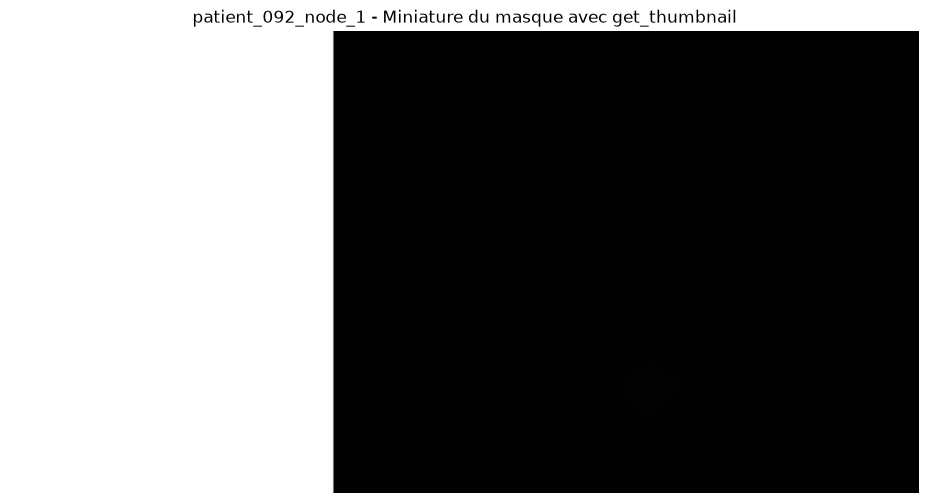

In [91]:
masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))
miniature_masque_get_thumbnail = masque.get_thumbnail((1000, 1000)) # Taille max (largeur/hauteur) en pixels
print("Taille de la miniature :", miniature_masque_get_thumbnail.size)

plt.figure(figsize=(12, 6))
plt.imshow(miniature_masque_get_thumbnail)
plt.axis("off")
plt.title("patient_092_node_1 - Miniature du masque avec get_thumbnail")
plt.show()

In [92]:
valeurs_miniature_masque = np.array(miniature_masque_get_thumbnail)
print(np.unique(valeurs_miniature_masque))

[  0   1   2   6 143 250 255]


On ne peut pas utiliser get_thumbnail tel quel pour les masques car :
- Pour une image classique, comme pour une lame ici, chaque pixel a trois valeurs (RGB, entre 0 et 255) correspondant aux trois canaux de l'image.
- Pour le masque, chaque pixel a ici une seule valeur : 0 (le fond), 1 (le tissu sain) ou 2 (la zone tumorale). Matplotlib affiche ici les valeurs sur une échelle de 0 à 255 donc 0, 1 et 2 apparaissent tous presque noirs. On pourrait le corriger en choisissant nos couleurs. Le problème est que get_thumbnail remplot les zones vides avec du blanc et fait la moyenne de pixels voisins donc on obtient des valeurs en dehors et 0, 1 et 2.

On va donc utiliser read_region qui ne fait pas ces "retouches" de get_thumbnail. On peut choisir un morceau de l'image si on le veut (get_thumbnail prend toute l'image), on choisit nous-même le niveau et on doit indiquer la taille exacte (pas la max).

In [93]:
niveau = 7
taille = masque.level_dimensions[niveau]

region_lame = lame.read_region((0, 0), niveau, taille)
region_masque = masque.read_region((0, 0), niveau, taille)

valeurs_lame = np.array(region_lame)
valeurs_masque = np.array(region_masque)[:, :, 0]

print("Taille lue au niveau", niveau, ":", taille)
print("Forme du tableau de la lame :", valeurs_lame.shape)
print("Forme du tableau du masque :", valeurs_masque.shape)
print("Valeurs présentes dans le masque :", np.unique(valeurs_masque))

Taille lue au niveau 7 : (1440, 732)
Forme du tableau de la lame : (732, 1440, 4)
Forme du tableau du masque : (732, 1440)
Valeurs présentes dans le masque : [0 1 2]


np.array transforme l’image en tableau de nombres (hauteur, largeur, canaux) avec 4 canaux pour RGB et la transparence A. Pour le masque on ne garde que le canal 0 qui contient 0, 1 ou 2.
OpenSlide donne la taille en largeur, hauteur d'où l'inversion.


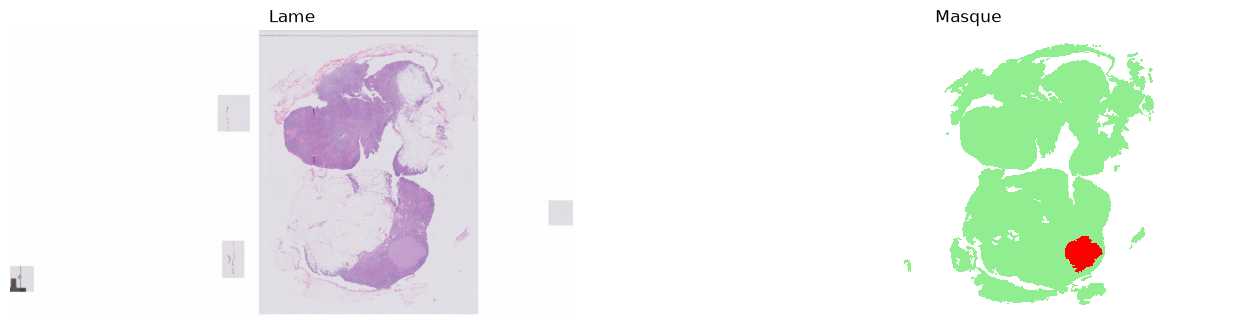

In [94]:
couleurs = ListedColormap(["white", "lightgreen", "red"]) # On liste les couleurs à utiliser pour 0, 1 et 2

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].imshow(valeurs_lame)
axes[0].set_title(f"Lame")
axes[0].axis("off")

axes[1].imshow(valeurs_masque, cmap=couleurs, vmin=0, vmax=2, interpolation="nearest")
axes[1].set_title("Masque")
axes[1].axis("off")

plt.show()

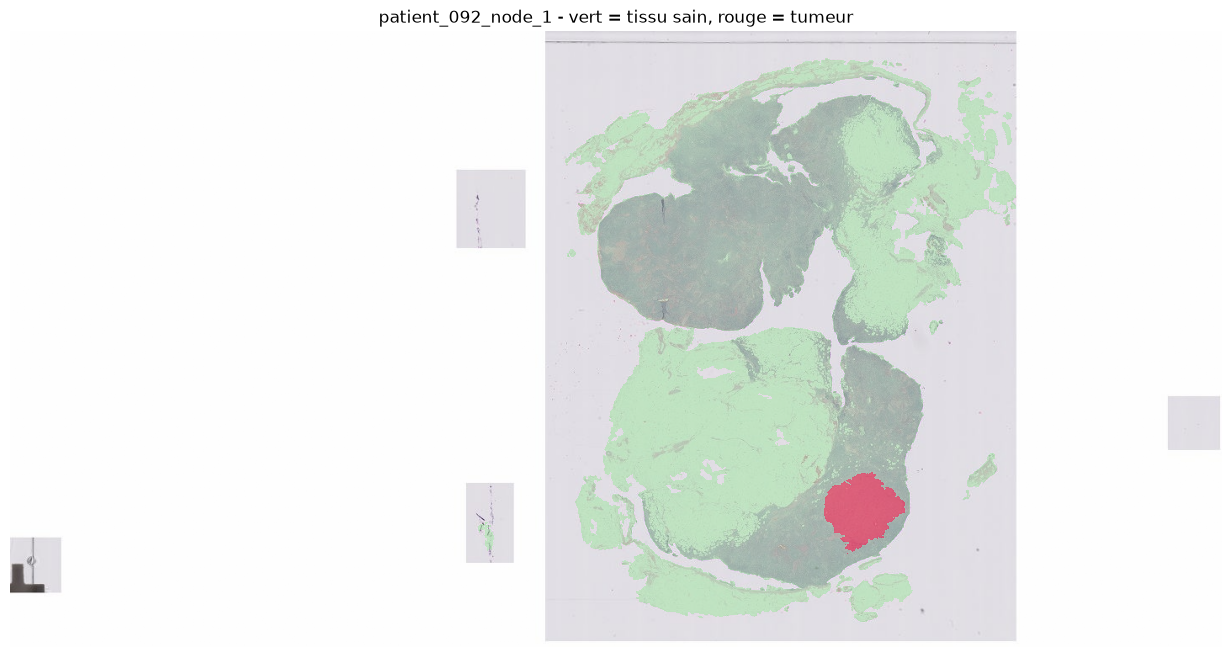

In [95]:
tissu_et_tumeur = np.ma.masked_where(valeurs_masque == 0, valeurs_masque) # On masque certains pixels 

plt.figure(figsize=(16, 8))
plt.imshow(valeurs_lame)
plt.imshow(tissu_et_tumeur, cmap=ListedColormap(["lightgreen", "red"]),
           vmin=1, vmax=2, alpha=0.4, interpolation="nearest")
plt.axis("off")
plt.title("patient_092_node_1 - vert = tissu sain, rouge = tumeur")
plt.show()

#### 5.1.3. Découper les lames en patchs

**Pourquoi faut-il découper les lames en patchs ?**

- L'image est beaucoup trop grande (pas possible avec les CNN)
- Si on réduisait l'image pour pouvoir utiliser un CNN, on perdrait le détail qui nous permet de voir les cellules tumorales
- Il y aurait trop peu d'exemples pour le modèle si on le faisait tourner sur les lames entières (une lame = une étiquette et l'étiquette ne dit pas où est la tumeur). C'est beaucoup plus précis avec les patchs.

**Les questions à se poser**

1. **Quelle surface choisir ? A quel niveau découper ? Quelle taille de patch choisir ?**
- Surface choisie : environ 100 à 200 µm soit assez pour voir un amas de cellules mais assez petit pour repérer les ITC
- Niveau 1 (0,5 µm par pixel) car une cellule tumorale y fait environ 20 pixels et c’est 4 fois moins coûteux que le niveau 0
- Taille de patch de 256 × 256 pixels (128 µm), proche des 224 pixels des modèles pré-entraînés

2. **Quel pas ?**
- 256 px, sans chevauchement, pour l’entraînement et la validation. 128 px avec 50 % de chevauchement pour analyser les lames entières.

3. **Comment repérer le tissu ?**
- Par les couleurs (saturation), pour toutes les lames. Le masque sert seulement aux étiquettes et à vérifier la détection.

4. **Combien de tissu minimum par patch ?**
- Au moins 25 %, mesuré sur le patch entier, avec la même règle pour tous les patchs.

5. **Comment étiqueter un patch ?**
- Tumoral s’il y a de la tumeur dans la zone centrale (128 × 128 px) et sain s’il n’y a aucune tumeur dans le patch, écarté sinon.

6. **Quel équilibre entre les classes ?**
- 50/50 : tous les patchs tumoraux, et autant de sains répartis entre les 3 lames d’entraînement.

7. **Comment enregistrer ?**
- Un tableau CSV et des PNG pour l’entraînement et la validation. Pour les lames entières, on lit les patchs à la volée et on enregistre seulement les prédictions.

> Cf Notion pour plus de précisions sur les décisions prises.

In [116]:
NIVEAU_PATCH = 1          # niveau de lecture des patchs (0,5 µm par pixel)
TAILLE_PATCH = 256        # côté du patch en pixels (128 µm)
PAS_ENTRAINEMENT = 256    # pas pour les patchs d'entraînement et de validation
TAILLE_CENTRE = 128       # largeur de la zone centrale pour l'étiquette
NIVEAU_TISSU = 5          # niveau réduit pour détecter le tissu
SEUIL_SATURATION = 0.04   # saturation minimale d'un pixel de tissu
SEUIL_TISSU = 0.25        # part minimale de tissu dans un patch
GRAINE = 42               # graine aléatoire pour les tirages (pour la reproductibilité)
QUOTA_TUMORAL = 1000      # nombre maximal de patchs tumoraux par lame (pour ne pas en avoir trop d'une même lame et limiter le nombre)

In [106]:
# Fonction pour lire une région en RGB

def lire_rgb(lame, position, niveau, taille):
    """Lit une région avec read_region et remplace les zones transparentes par du blanc."""
    region = lame.read_region(position, niveau, taille)
    image = Image.new("RGB", region.size, (255, 255, 255))
    image.paste(region, mask=region.split()[3])
    return image

# region.split() sépare l’image en ses canaux. On obtient 4 images à un seul canal (R, G, B, A).
# [3] prend la quatrième donc le canal A. C’est une image où chaque pixel vaut 255 ou 0 (si transparent).
# image.paste(region, mask=...) colle region sur l’image blanche et le paramètre mask dit, pixel par pixel, si on colle ou non : si A vaut 0 = False, on ne colle rien et le blanc reste.

read_region renvoie une image RGBA et on a besoin de la convertir en RGB pour le modèle (c'est ce qu'il attend). Or, si on la convertit directement en RGB, les zones transparentes (donc non numérisées) deviennent noires car un pixel vide = (0,0,0,0) et donc en RGA (0,0,0). 
Cette fonction crée une image blanche puis colle la région par-dessus. Ainsi, les zones transparentes restent blanches.

In [ ]:
# Fonction qui détecte le tissu en fonction de la couleur (saturation)

def masque_tissu(lame, niveau=NIVEAU_TISSU, seuil=SEUIL_SATURATION):
    """Renvoie un tableau de booléens : True là où il y a du tissu (saturation au-dessus du seuil)."""
    region = np.array(lame.read_region((0, 0), niveau, lame.level_dimensions[niveau])) # On obtient un tableau Numpy à 3 dimensions rempli de nombres entre 0 et 255 (on en a besoin pour faire des calculs sur les pixels, ici ceux transparents par ex)
    rgb = region[:, :, :3].copy() # region[:, :, :3] garde R, G et B
    rgb[region[:, :, 3] == 0] = 255 # On met en blanc les pixels transparents (region[:, :, 3] == 0 -> on met 255 dans les trois canaux pour tous ces pixels)
    hsv = np.array(Image.fromarray(rgb).convert("HSV")) # Image.fromarray(rgb).convert("HSV") convertit en HSV qui nous permet d'avoir la saturation
    saturation = hsv[:, :, 1] / 255 # Le canal 1 est la saturation entre 0 et 255 qu’on divise par 255 pour l’avoir entre 0 et 1 qui est l'échelle de la saturation
    return saturation > seuil # saturation > seuil donne un tableau de True/False qui correspond à notre masque de tissu

On lit toute la lame au niveau 5 pour que ce soit plus rapide qu'à un niveau inférieur et c'est suffisant pour détecter le tissu.

Part de la lame détectée comme tissu (couleurs) : 0.141
Part de la lame en tissu selon le masque officiel : 0.203
Part du tissu officiel retrouvée par notre détection : 0.68
Part de notre tissu qui est aussi du tissu officiel : 0.978


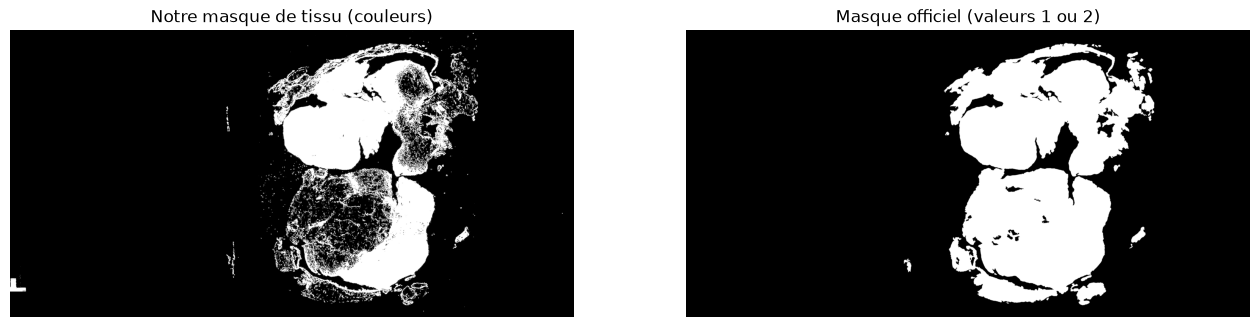

In [ ]:
# Comparaison de notre détection du tissu au masque officiel

masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))
masque_reduit = np.array(masque.read_region((0, 0), NIVEAU_TISSU, masque.level_dimensions[NIVEAU_TISSU]))[:, :, 0] # On garde le canal 0 qui contient 0, 1 ou 2

tissu = masque_tissu(lame) # Renvoie un tableau de True (pour le tissu) /False (pour le fond)
tissu_officiel = masque_reduit > 0 # Idem

print("Part de la lame détectée comme tissu (couleurs) :", round(tissu.mean(), 3))
print("Part de la lame en tissu selon le masque officiel :", round(tissu_officiel.mean(), 3))
print("Part du tissu officiel retrouvée par notre détection :", round((tissu & tissu_officiel).sum() / tissu_officiel.sum(), 3))
print("Part de notre tissu qui est aussi du tissu officiel :", round((tissu & tissu_officiel).sum() / tissu.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(tissu, cmap="gray")
axes[0].set_title("Notre masque de tissu (couleurs)")
axes[0].axis("off")
axes[1].imshow(tissu_officiel, cmap="gray")
axes[1].set_title("Masque officiel (valeurs 1 ou 2)")
axes[1].axis("off")
plt.show()


Résultats sur la lame 092 : 
- 98 % de ce qu’on détecte est bien du tissu (presque aucune fausse détection) et on retrouve 68 % du tissu officiel. 
- Ce qu’on manque ce sont surtout des zones très pâles que le masque officiel compte comme tissu mais ce n’est pas gênant car aucun patch tumoral n’est perdu (voir plus bas).
- Par contre on voit ici qu'on a pris un petit bout en bas à gauche alors que ce n'est pas du tissu. Ca ajoute quelques faux patchs sains.

In [ ]:
# Fonction qui liste les patchs et les étiquettes
# Elle parcourt l'image patch par patch
# Si patch sans tissu : exclu
# Si patch avec tissu, elle regarde si s'il y a de la tumeur ou non pour l'étiqueter
# Elle écarte les patchs avec .........

def lister_patchs(nom_lame, nom_set, pas=PAS_ENTRAINEMENT):
    """Parcourt la lame sur une grille et renvoie un tableau des patchs qui contiennent du tissu."""
    lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
    masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, nom_lame + "_mask.tif"))
    tissu = masque_tissu(lame)

    facteur_patch = int(lame.level_downsamples[NIVEAU_PATCH]) # Permet de savoir de combien on réduit par rapport au niveau 0 car read_me attend ses positions dans le repère du niveau 0
    facteur_tissu = int(lame.level_downsamples[NIVEAU_TISSU]) # Idem
    taille_0 = TAILLE_PATCH * facteur_patch      # Combien fait de côté le patch, en pixels du niveau 0 !
    pas_0 = pas * facteur_patch                  # Idem pour le pas : en pixels du niveau 0
    debut_centre = (TAILLE_PATCH - TAILLE_CENTRE) // 2 # A quelle position commence le centre qu'on a définit
    fin_centre = debut_centre + TAILLE_CENTRE # La fin du centre
    largeur_0, hauteur_0 = lame.dimensions # Dimensions de la lame

    patchs = [] # Contiendra une ligne par patch
    for y in range(0, hauteur_0 - taille_0 + 1, pas_0): # On parcourt chaque "ligne" de 512 px de hauteur. A noter : si patch incomplet en fin de ligne, il est écarté
        for x in range(0, largeur_0 - taille_0 + 1, pas_0): # Et pour chaque ligne, chaque colone de 512 px de largeur
            zone_tissu = tissu[y // facteur_tissu:(y + taille_0) // facteur_tissu,
                               x // facteur_tissu:(x + taille_0) // facteur_tissu]
            # Le patch, lui est repéré en coordonnées du niveau 0 : il va de x à x + 512 en largeur et de y à y + 512 en hauteur.
            # Pour trouver le même carré dans tissu, on divise ses 4 bords par 32
            # zone_tissu est donc un petit tableau de 16 × 16 cases (512/32) True/False qui se trouvent sous le patch.            
            pct_tissu = zone_tissu.mean() # On calcule la part de tissu dans le carré
            if pct_tissu == 0:
                continue

            zone_masque = np.array(masque.read_region((x, y), NIVEAU_PATCH, (TAILLE_PATCH, TAILLE_PATCH)))[:, :, 0] # On regarde dans la masque "officiel" dans le canal 0 qui contient 0, 1 ou 2
            pct_tumeur = (zone_masque == 2).mean()
            pct_tumeur_centre = (zone_masque[debut_centre:fin_centre, debut_centre:fin_centre] == 2).mean()

            if pct_tumeur_centre > 0:
                etiquette = "tumoral"
            elif pct_tumeur == 0:
                etiquette = "sain"
            else:
                etiquette = "ecarte"
            # On garde les patchs sans tumeur dans tout le patch, ceux avec tumeur au centre mais on écartera ceux avec tumeur juste au bord car cas ambigu pour l'entrainement

            patchs.append({
                "lame": nom_lame, "set": nom_set, "x": x, "y": y, "niveau": NIVEAU_PATCH,
                "pct_tissu": round(pct_tissu, 3), "pct_tumeur": round(pct_tumeur, 4),
                "pct_tumeur_centre": round(pct_tumeur_centre, 4),
                "assez_de_tissu": pct_tissu >= SEUIL_TISSU, "etiquette": etiquette,
            })
    return pd.DataFrame(patchs)

In [111]:
# On applique aux lames d’entraînement et de validation

selection = pd.read_csv("../data/prototype/selection_lames_prototype.csv")
lames_patchs = selection[selection["set"].isin(["entrainement", "validation"])] # On applique qu'aux lames de validation et entrainement

tableaux = [] # On obtiendra une liste de dataframes (un df par lame)
for _, ligne in lames_patchs.iterrows():
    debut = time.time() # L'heure au début du traitement
    tableau = lister_patchs(ligne["lame"], ligne["set"]) # Le dataframe d'une lame
    tableaux.append(tableau) 
    print(f"{ligne['lame']} : {len(tableau)} patchs avec du tissu ({time.time() - debut:.0f} s)")

candidats = pd.concat(tableaux, ignore_index=True) # Empile les dataframes

patient_089_node_3 : 7577 patchs avec du tissu (9 s)
patient_096_node_0 : 16493 patchs avec du tissu (30 s)
patient_083_node_4 : 2994 patchs avec du tissu (4 s)
patient_092_node_1 : 13872 patchs avec du tissu (20 s)


In [113]:
# On regarde les patchs obtenus, par lame et catégorie (a écarter, sain, tumoral)

peu_de_tissu = ~candidats["assez_de_tissu"]
ambigu = candidats["etiquette"] == "ecarte"
ecartes = candidats[peu_de_tissu | ambigu].copy()
utilisables = candidats[~peu_de_tissu & ~ambigu]

ecartes["raison"] = "ambigu"
ecartes.loc[~ecartes["assez_de_tissu"], "raison"] = "peu de tissu"

print("Patchs utilisables :")
display(pd.crosstab([utilisables["set"], utilisables["lame"]], utilisables["etiquette"], margins=True))

print("Patchs écartés :")
display(pd.crosstab([ecartes["set"], ecartes["lame"]], ecartes["raison"], margins=True))

perdus = ecartes[(ecartes["raison"] == "peu de tissu") & (ecartes["etiquette"] == "tumoral")]
print("Patchs tumoraux écartés par le seuil de tissu :", len(perdus))

Patchs utilisables :


etiquette                         sain  tumoral    All
set          lame                                     
entrainement patient_083_node_4   2859        0   2859
             patient_089_node_3   6603        7   6610
             patient_096_node_0   7455     7725  15180
validation   patient_092_node_1  10942      388  11330
All                              27859     8120  35979

Patchs écartés :


raison                           ambigu  peu de tissu   All
set          lame                                          
entrainement patient_083_node_4       0           135   135
             patient_089_node_3       6           961   967
             patient_096_node_0     190          1123  1313
validation   patient_092_node_1      29          2513  2542
All                                 225          4732  4957

Patchs tumoraux écartés par le seuil de tissu : 0


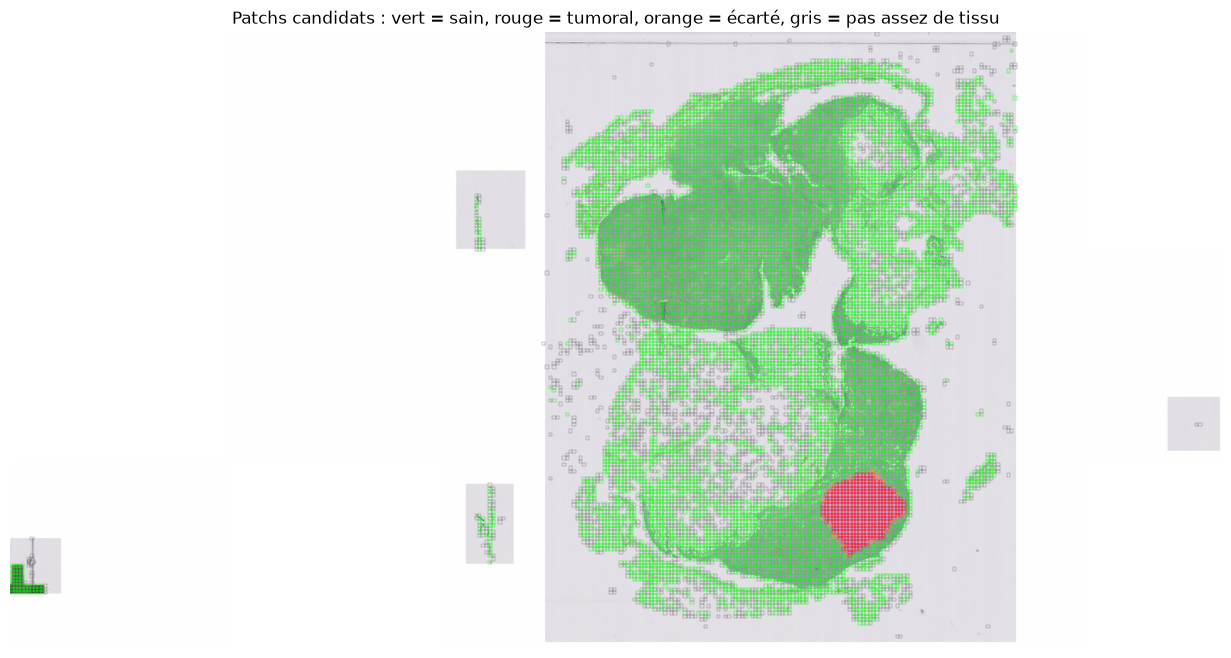

In [115]:
# Voir les patchs sur la lame pour vérifier (ex avec patient_092_node_1)

nom_lame = "patient_092_node_1"
lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
niveau_vue = 6 # Juste pour l'affichage ici donc niveau élevé
vue = lire_rgb(lame, (0, 0), niveau_vue, lame.level_dimensions[niveau_vue])
facteur_vue = lame.level_downsamples[niveau_vue] # Donne le facteur pour la vue de niveau 6
taille_vue = TAILLE_PATCH * lame.level_downsamples[NIVEAU_PATCH] / facteur_vue # Patch au niveau 1 vs vue au niveau 6 donc on réduit la taille du ptach (en passant par le niveau 0)
couleurs = {"sain": "lime", "tumoral": "red", "ecarte": "orange"}

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(vue)
for _, p in candidats[candidats["lame"] == nom_lame].iterrows():
    couleur = couleurs[p["etiquette"]] if p["assez_de_tissu"] else "gray"
    ax.add_patch(Rectangle((p["x"] / facteur_vue, p["y"] / facteur_vue), taille_vue, taille_vue,
                           fill=False, edgecolor=couleur, linewidth=0.3))
ax.set_title("Patchs candidats : vert = sain, rouge = tumoral, orange = écarté, gris = pas assez de tissu")
ax.axis("off")
plt.show()

In [120]:
# Choix final des patchs

morceaux = [] # Contiendra les patchs choisis sous forme d'un df par paquet choisi
for nom_set in ["entrainement", "validation"]:
    patchs_set = utilisables[utilisables["set"] == nom_set]
    lames_set = patchs_set["lame"].unique()

    # On prend tous les patchs tumoraux dans la limite définie par lame (1000)
    nb_tumoraux = 0
    for nom_lame in lames_set:
        tumoraux_lame = patchs_set[(patchs_set["lame"] == nom_lame) & (patchs_set["etiquette"] == "tumoral")] # On prend tous les patchs tumoraux de la lame
        choisis = tumoraux_lame.sample(n=min(len(tumoraux_lame), QUOTA_TUMORAL), random_state=GRAINE) # On en tire au hasard 1000 s'il y en a plus
        morceaux.append(choisis) # On les ajoute à la liste morceaux
        nb_tumoraux += len(choisis)

    # On prend des patchs sains répartis à parts égales entre les lames dans la même proportion que les tumoraux
    nb_sains_par_lame = nb_tumoraux // len(lames_set)
    for nom_lame in lames_set:
        sains_lame = patchs_set[(patchs_set["lame"] == nom_lame) & (patchs_set["etiquette"] == "sain")]
        choisis = sains_lame.sample(n=min(len(sains_lame), nb_sains_par_lame), random_state=GRAINE)
        morceaux.append(choisis)

echantillon = pd.concat(morceaux, ignore_index=True) # On empile dans un seul df

display(pd.crosstab([echantillon["set"], echantillon["lame"]], echantillon["etiquette"], margins=True))

etiquette                        sain  tumoral   All
set          lame                                   
entrainement patient_083_node_4   335        0   335
             patient_089_node_3   335        7   342
             patient_096_node_0   335     1000  1335
validation   patient_092_node_1   388      388   776
All                              1393     1395  2788

In [ ]:
# Enregistrement des patchs

os.makedirs("../data/prototype/patchs", exist_ok=True)
DOSSIER_PATCHS = "../data/prototype/patchs"

debut = time.time()
for nom_lame in echantillon["lame"].unique():
    lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
    patchs_lame = echantillon[echantillon["lame"] == nom_lame]
    for index, p in patchs_lame.iterrows(): # On parcourt les patchs
        dossier = os.path.join(DOSSIER_PATCHS, p["set"], p["etiquette"]) # On construit le dossier de destination pour l'enregistrement
        os.makedirs(dossier, exist_ok=True) #On crée le dossier si non existant
        nom_fichier = f"{nom_lame}_x{p['x']}_y{p['y']}.png" # Nom du fichier construit sur la base de la lame et la position du patch
        image = lire_rgb(lame, (int(p["x"]), int(p["y"])), NIVEAU_PATCH, (TAILLE_PATCH, TAILLE_PATCH)) # On découpe le patch
        image.save(os.path.join(dossier, nom_fichier)) # On l'enregistre
        echantillon.loc[index, "fichier"] = os.path.join(p["set"], p["etiquette"], nom_fichier) # On note dans le df, sur la ligne du patch, où l'image est enregistrée
    print(f"{nom_lame} : {len(patchs_lame)} patchs enregistrés")

echantillon.to_csv(os.path.join(DOSSIER_PATCHS, "patchs.csv"), index=False) # On enregistre l tableau en csv

print(f"Terminé en {time.time() - debut:.0f} s")

patient_089_node_3 : 342 patchs enregistrés
patient_096_node_0 : 1335 patchs enregistrés
patient_083_node_4 : 335 patchs enregistrés
patient_092_node_1 : 776 patchs enregistrés
Terminé en 24 s


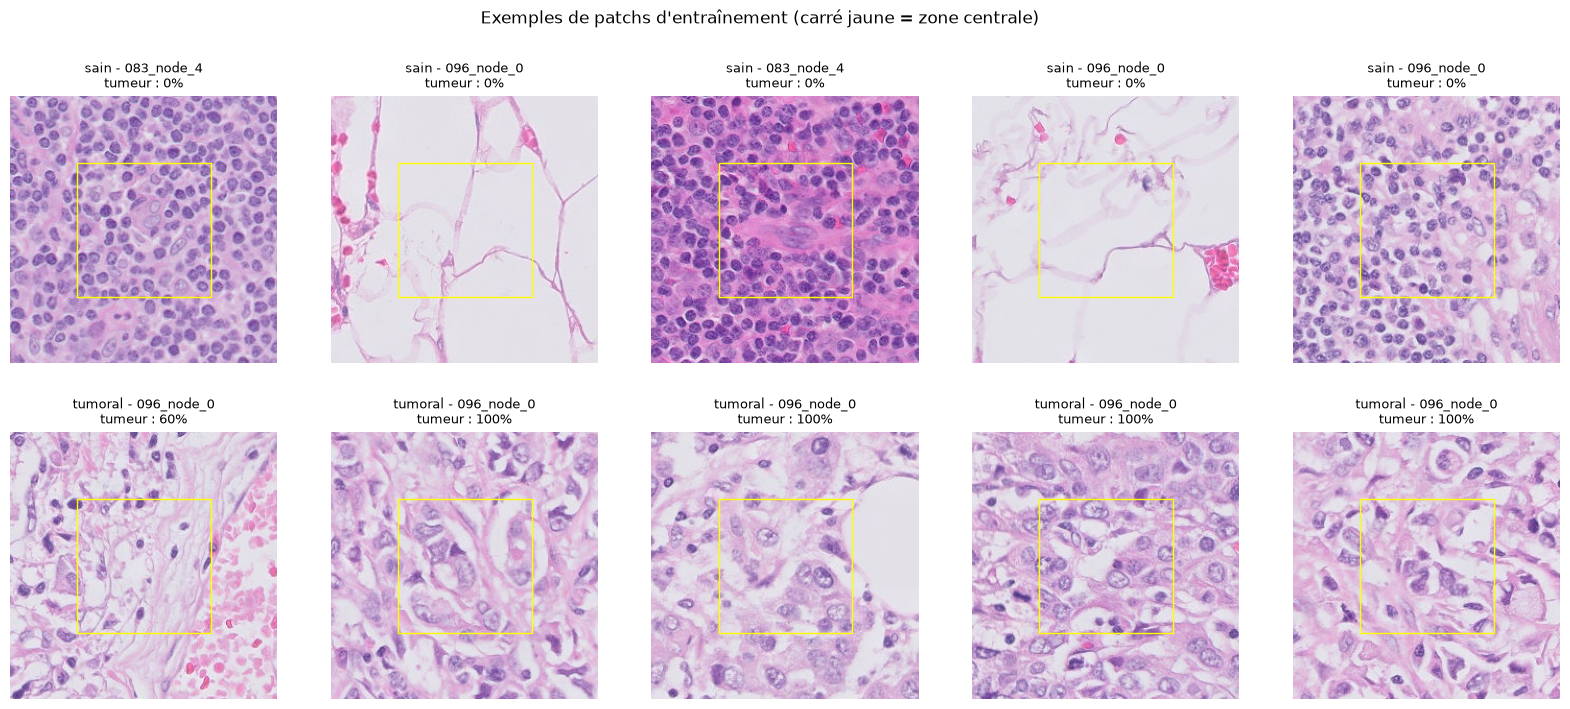

In [ ]:
# Vérification visuelle des patchs (à partir de quelques exemples)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
debut_centre = (TAILLE_PATCH - TAILLE_CENTRE) // 2
for i, etiquette in enumerate(["sain", "tumoral"]):
    exemples = echantillon[(echantillon["set"] == "entrainement") & (echantillon["etiquette"] == etiquette)].sample(n=5, random_state=GRAINE)
    for j, (_, p) in enumerate(exemples.iterrows()):
        image = Image.open(os.path.join(DOSSIER_PATCHS, p["fichier"]))
        axes[i, j].imshow(image)
        axes[i, j].add_patch(Rectangle((debut_centre, debut_centre), TAILLE_CENTRE, TAILLE_CENTRE,
                                       fill=False, edgecolor="yellow", linewidth=1))
        axes[i, j].set_title(f"{etiquette} - {p['lame'][8:]}\ntumeur : {p['pct_tumeur']:.0%}", fontsize=9)
        axes[i, j].axis("off")
plt.suptitle("Exemples de patchs d'entraînement (carré jaune = zone centrale)")
plt.show()

#### 5.1.4. Entrainement du modèle de patchs

In [105]:
lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, "patient_092_node_1.tif"))
masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))

for nom, image in [("Lame", lame), ("Masque", masque)]:
    largeur, hauteur = image.level_dimensions[0]
    print(f"{nom} : niveau 0 = {largeur} x {hauteur} pixels, "
          f"{image.properties.get('openslide.mpp-x')} µm par pixel, "
          f"{image.level_count} niveaux")

Lame : niveau 0 = 184320 x 93696 pixels, 0.25 µm par pixel, 10 niveaux
Masque : niveau 0 = 184320 x 93696 pixels, 0.25 µm par pixel, 10 niveaux


> Les masques ont la même taille que les lames au niveau 0 avec la même taille de pixels. On pourra donc les utiliser plutôt que les annotations (cf la question restée posée à ce sujet en partie 5.1.1.) car la résolution est précise.

### 5.2. Etape 2 - Du patch à la lame

### 5.3. Etape 3 - De la lame à la patiente